Vekil Modelin Kara Kutuyu Taklit Etme Başarısı (R² Skoru): 0.86


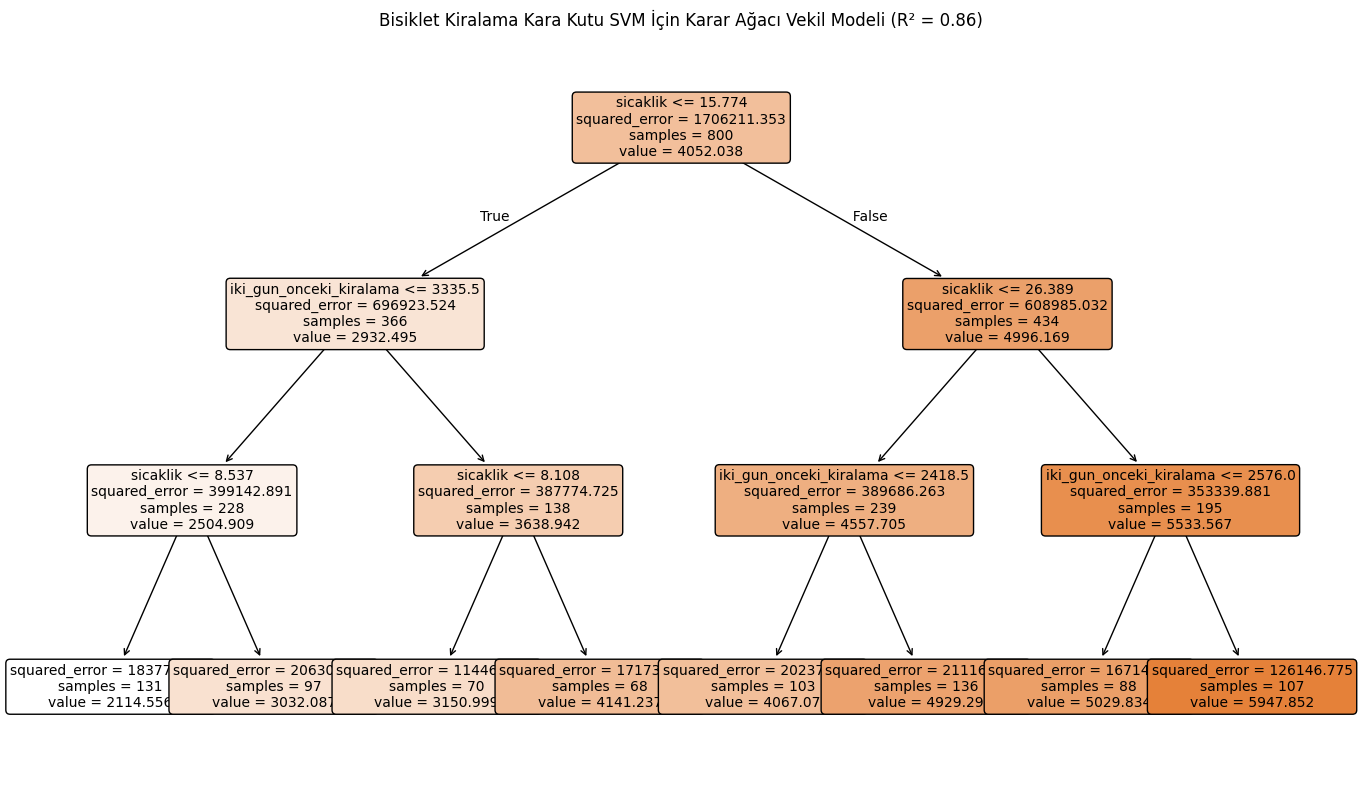

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score

# 1. Sentetik Bisiklet Kiralama Veri Seti Oluşturma
np.random.seed(42)
n_samples = 1000

temperature = np.random.uniform(0, 35, n_samples)  # °C cinsinden sıcaklık
wind_speed = np.random.uniform(0, 30, n_samples)   # km/s rüzgar hızı
is_weekend = np.random.choice([0, 1], size=n_samples) # Hafta sonu mu?
rentals_2days_ago = np.random.randint(100, 5000, n_samples) # 2 gün önceki kiralama sayısı

# Gerçek hedef değişkeni (Karmaşık non-linear ilişki + gürültü)
y = (
    1000
    + 120 * temperature
    - 0.8 * (temperature - 15)**2
    - 15 * wind_speed
    + 0.4 * rentals_2days_ago
    + 500 * is_weekend
    + np.random.normal(0, 300, n_samples)
)

X = pd.DataFrame({
    'sicaklik': temperature,
    'ruzgar_hizi': wind_speed,
    'hafta_sonu': is_weekend,
    'iki_gun_onceki_kiralama': rentals_2days_ago
})

# Veriyi Eğitim ve Test Setine Ayırma
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2)

# 2. Kara Kutu Modeli Eğitme (Ölçeklendirme ile SVM / SVR)
black_box_model = make_pipeline(StandardScaler(), SVR(kernel='rbf', C=1000, gamma=0.1))
black_box_model.fit(X_train, y_train)

# 3. Vekil Modeli (Surrogate CART) Eğitme
# Önemli: Vekil model, gerçek y değerlerini değil, Kara Kutu'nun ürettiği tahminleri (y_hat) öğrenir.
y_train_hat = black_box_model.predict(X_train)
y_test_hat = black_box_model.predict(X_test)

surrogate_tree = DecisionTreeRegressor(max_depth=3, random_state=42)
surrogate_tree.fit(X_train, y_train_hat)

# 4. Vekil Modelin Sadakat (Fidelity) Değerlendirmesi
surrogate_preds = surrogate_tree.predict(X_test)
fidelity_r2 = r2_score(y_test_hat, surrogate_preds)

print(f"Vekil Modelin Kara Kutuyu Taklit Etme Başarısı (R² Skoru): {fidelity_r2:.2f}")

# 5. Karar Ağacının Görselleştirilmesi
plt.figure(figsize=(14, 8))
plot_tree(
    surrogate_tree,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title(f"Bisiklet Kiralama Kara Kutu SVM İçin Karar Ağacı Vekil Modeli (R² = {fidelity_r2:.2f})")
plt.tight_layout()
plt.show()